In [2]:
import os, json
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from sklearn.metrics import confusion_matrix, classification_report

tf.keras.utils.set_random_seed(42)

DATA = r"..\data\dataset0"
IMG = 224
BATCH = 32

print("TensorFlow:", tf.__version__)
print("Isi folder:", os.listdir(DATA))

TensorFlow: 2.21.0
Isi folder: ['test', 'train']


In [3]:
def muat(sub, subset=None, shuffle=True):
    return tf.keras.utils.image_dataset_from_directory(
        os.path.join(DATA, sub),
        image_size=(IMG, IMG), batch_size=BATCH,
        validation_split=0.15 if subset else None,
        subset=subset, seed=42, shuffle=shuffle)

train_ds = muat("train", "training")      # 85% dari folder train
val_ds = muat("train", "validation")      # 15% dari folder train
test_ds = muat("test", shuffle=False)     # folder test

kelas = train_ds.class_names
print("Kelas:", kelas)

Found 2765 files belonging to 3 classes.
Using 2351 files for training.
Found 2765 files belonging to 3 classes.
Using 414 files for validation.
Found 693 files belonging to 3 classes.
Kelas: ['ripe_banana', 'unripe_banana', 'very_ripe_banana']


In [4]:
import collections, glob

for sub in ["train", "test"]:
    print(f"\n{sub}:")
    for k in sorted(os.listdir(os.path.join(DATA, sub))):
        n = len(glob.glob(os.path.join(DATA, sub, k, "*")))
        print(f"  {k}: {n}")


train:
  ripe_banana: 924
  unripe_banana: 914
  very_ripe_banana: 927

test:
  ripe_banana: 232
  unripe_banana: 229
  very_ripe_banana: 232


In [7]:
import hashlib

def hash_file(p):
    with open(p, "rb") as f:
        return hashlib.md5(f.read()).hexdigest()

def kumpulkan(sub):
    return {hash_file(p) for p in glob.glob(os.path.join(DATA, sub, "*", "*"))}

irisan = kumpulkan("train") & kumpulkan("test")
print("Citra identik di train dan test:", len(irisan))

Citra identik di train dan test: 0


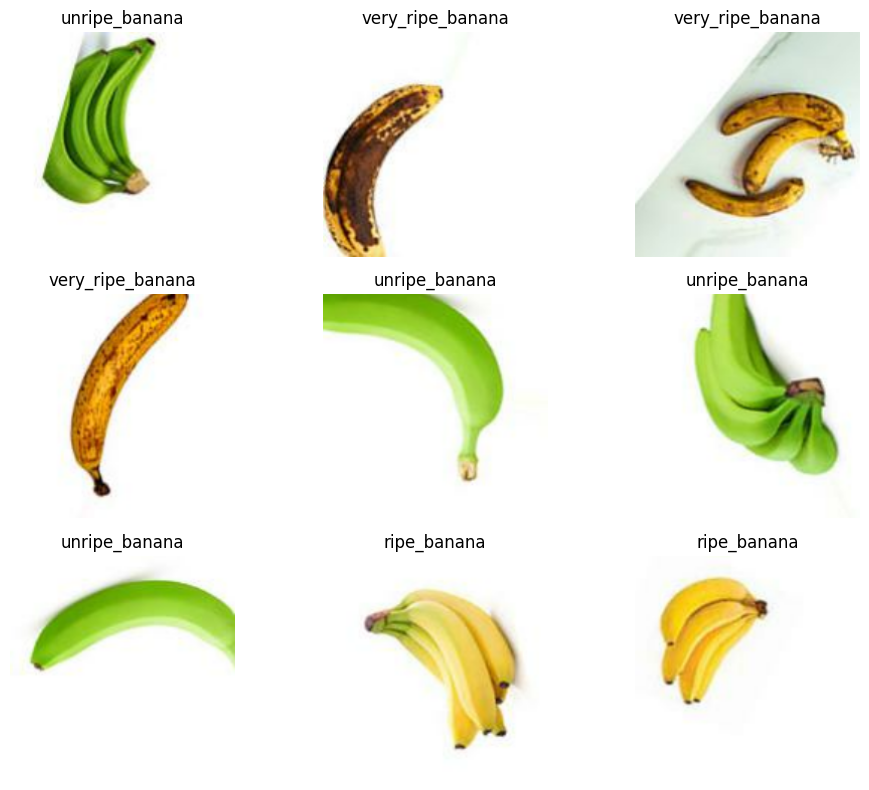

In [8]:
plt.figure(figsize=(10, 8))
for imgs, lbls in train_ds.take(1):
    for i in range(9):
        plt.subplot(3, 3, i + 1)
        plt.imshow(imgs[i].numpy().astype("uint8"))
        plt.title(kelas[lbls[i]])
        plt.axis("off")
plt.tight_layout(); plt.show()

In [9]:
augmentasi = models.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.2),
])

def blok(f):
    return [layers.Conv2D(f, 3, padding="same", activation="relu"),
            layers.BatchNormalization(),
            layers.MaxPooling2D()]

model = models.Sequential(
    [layers.Input((IMG, IMG, 3)), augmentasi, layers.Rescaling(1./255)]
    + blok(32) + blok(64) + blok(128) + blok(256)
    + [layers.GlobalAveragePooling2D(),
       layers.Dropout(0.4),
       layers.Dense(128, activation="relu"),
       layers.Dense(len(kelas), activation="softmax")]
)

model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ sequential (Sequential)              │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ rescaling (Rescaling)                │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d (Conv2D)                      │ (None, 224, 224, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization                  │ (None, 224, 224, 32)        │             128 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 112, 112, 32)        │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 112, 112, 64)        │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_1                │ (None, 112, 112, 64)        │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 56, 56, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 56, 56, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_2                │ (None, 56, 56, 128)         │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 28, 28, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_3 (Conv2D)                    │ (None, 28, 28, 256)         │         295,168 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_3                │ (None, 28, 28, 256)         │           1,024 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_3 (MaxPooling2D)       │ (None, 14, 14, 256)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 256)                 │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │          32,896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 3)                   │             387 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 423,619 (1.62 MB)

 Trainable params: 422,659 (1.61 MB)

 Non-trainable params: 960 (3.75 KB)

In [10]:
os.makedirs("../models", exist_ok=True)

cb = [EarlyStopping(patience=5, restore_best_weights=True),
      ModelCheckpoint("../models/banana_cnn.keras", save_best_only=True)]

history = model.fit(train_ds, validation_data=val_ds, epochs=30, callbacks=cb)

Epoch 1/30
74/74 ━━━━━━━━━━━━━━━━━━━━ 126s 2s/step - accuracy: 0.9796 - loss: 0.0584 - val_accuracy: 0.3140 - val_loss: 1.9335
Epoch 2/30
74/74 ━━━━━━━━━━━━━━━━━━━━ 119s 2s/step - accuracy: 0.9940 - loss: 0.0192 - val_accuracy: 0.4686 - val_loss: 1.6320
Epoch 3/30
74/74 ━━━━━━━━━━━━━━━━━━━━ 116s 2s/step - accuracy: 0.9962 - loss: 0.0095 - val_accuracy: 0.4420 - val_loss: 1.3198
Epoch 4/30
74/74 ━━━━━━━━━━━━━━━━━━━━ 120s 2s/step - accuracy: 0.9983 - loss: 0.0064 - val_accuracy: 0.3454 - val_loss: 1.8910
Epoch 5/30
74/74 ━━━━━━━━━━━━━━━━━━━━ 115s 2s/step - accuracy: 0.9966 - loss: 0.0151 - val_accuracy: 0.6643 - val_loss: 1.9796
Epoch 6/30
74/74 ━━━━━━━━━━━━━━━━━━━━ 114s 2s/step - accuracy: 0.9881 - loss: 0.0372 - val_accuracy: 0.4058 - val_loss: 7.3133
Epoch 7/30
74/74 ━━━━━━━━━━━━━━━━━━━━ 124s 2s/step - accuracy: 0.9966 - loss: 0.0118 - val_accuracy: 0.9903 - val_loss: 0.0475
Epoch 8/30
74/74 ━━━━━━━━━━━━━━━━━━━━ 119s 2s/step - accuracy: 0.9996 - loss: 0.0018 - val_accuracy: 0.9662 - v

In [11]:
print("Jumlah epoch yang dijalankan:", len(history.history["loss"]))

Jumlah epoch yang dijalankan: 18


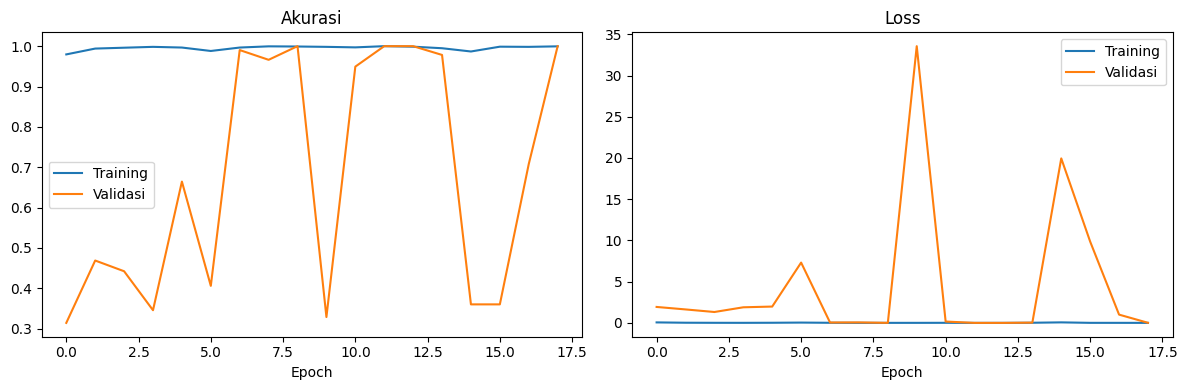

In [12]:
h = history.history
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(h["accuracy"], label="Training"); ax[0].plot(h["val_accuracy"], label="Validasi")
ax[0].set_title("Akurasi"); ax[0].set_xlabel("Epoch"); ax[0].legend()
ax[1].plot(h["loss"], label="Training"); ax[1].plot(h["val_loss"], label="Validasi")
ax[1].set_title("Loss"); ax[1].set_xlabel("Epoch"); ax[1].legend()
plt.tight_layout(); plt.show()

22/22 ━━━━━━━━━━━━━━━━━━━━ 6s 257ms/step - accuracy: 1.0000 - loss: 1.5522e-05
Akurasi data uji: 100.00%
22/22 ━━━━━━━━━━━━━━━━━━━━ 6s 249ms/step
                  precision    recall  f1-score   support

     ripe_banana       1.00      1.00      1.00       232
   unripe_banana       1.00      1.00      1.00       229
very_ripe_banana       1.00      1.00      1.00       232

        accuracy                           1.00       693
       macro avg       1.00      1.00      1.00       693
    weighted avg       1.00      1.00      1.00       693



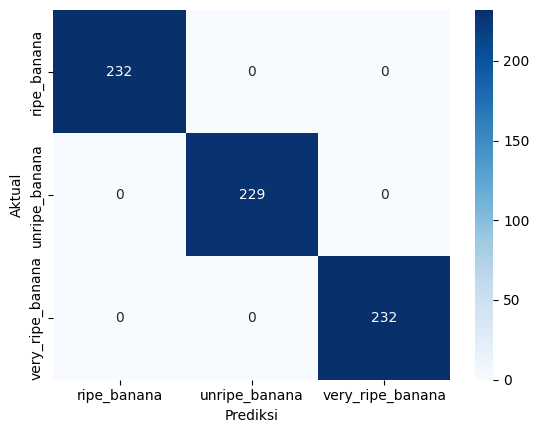

In [13]:
loss, acc = model.evaluate(test_ds)
print(f"Akurasi data uji: {acc*100:.2f}%")

y_true = np.concatenate([y.numpy() for _, y in test_ds])
y_pred = np.argmax(model.predict(test_ds), axis=1)

print(classification_report(y_true, y_pred, target_names=kelas))

cm = confusion_matrix(y_true, y_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=kelas, yticklabels=kelas)
plt.xlabel("Prediksi"); plt.ylabel("Aktual"); plt.show()

In [14]:
from PIL import Image, ImageOps

def dhash(path, flip=False, size=8):
    img = Image.open(path).convert("L")
    if flip:
        img = ImageOps.mirror(img)
    img = img.resize((size + 1, size))
    a = np.asarray(img, dtype=np.int16)
    return (a[:, 1:] > a[:, :-1]).flatten()

def daftar(sub):
    return sorted(glob.glob(os.path.join(DATA, sub, "*", "*")))

tr_paths, te_paths = daftar("train"), daftar("test")
tr_h = np.array([dhash(p) for p in tr_paths])
te_h = np.array([dhash(p) for p in te_paths])
te_hf = np.array([dhash(p, flip=True) for p in te_paths])

jarak = np.array([
    min((tr_h != a).sum(axis=1).min(), (tr_h != b).sum(axis=1).min())
    for a, b in zip(te_h, te_hf)
])

print("Median jarak terdekat:", np.median(jarak))
for t in (0, 3, 6, 10):
    print(f"Citra test dengan kembaran di train (jarak <= {t}): {(jarak <= t).sum()} dari {len(jarak)}")

Median jarak terdekat: 7.0
Citra test dengan kembaran di train (jarak <= 0): 3 dari 693
Citra test dengan kembaran di train (jarak <= 3): 87 dari 693
Citra test dengan kembaran di train (jarak <= 6): 342 dari 693
Citra test dengan kembaran di train (jarak <= 10): 610 dari 693


In [15]:
foto_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join("..", "data", "foto_sendiri"),
    image_size=(IMG, IMG), batch_size=BATCH, shuffle=False,
    class_names=kelas)

yt = np.concatenate([y.numpy() for _, y in foto_ds])
yp = np.argmax(model.predict(foto_ds), axis=1)

print(classification_report(yt, yp, target_names=kelas))
print(confusion_matrix(yt, yp))

FileNotFoundError: [WinError 3] The system cannot find the path specified: '..\\data\\foto_sendiri'

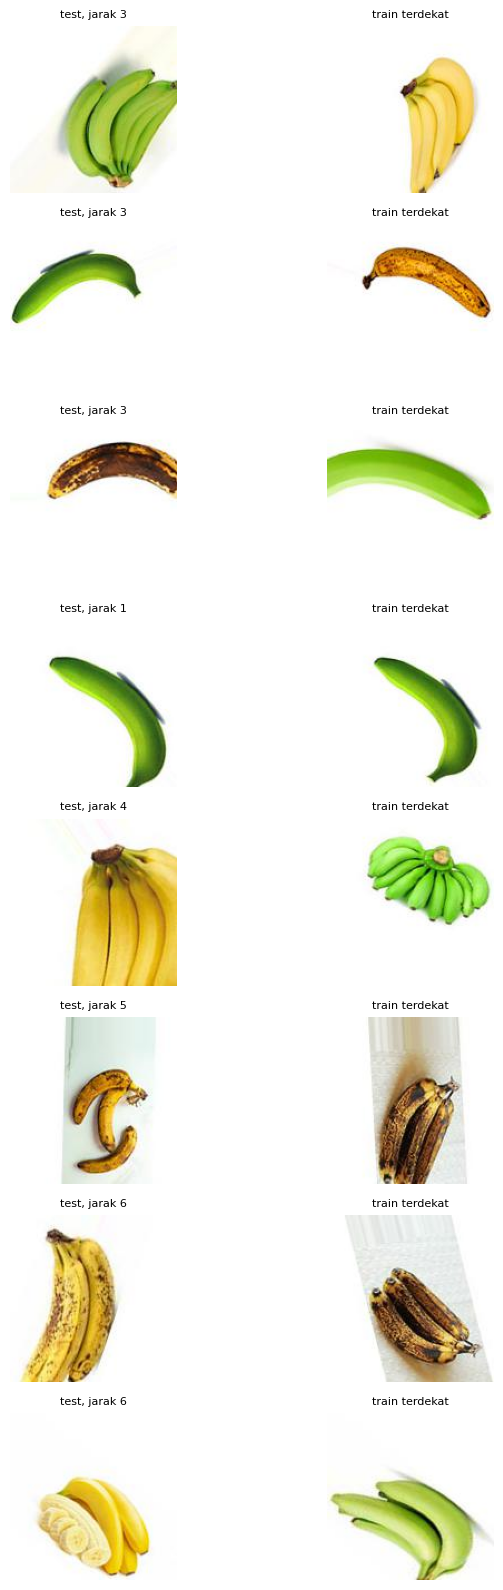

In [16]:
d_n = np.array([(tr_h != a).sum(axis=1) for a in te_h])
d_f = np.array([(tr_h != b).sum(axis=1) for b in te_hf])
jarak = np.minimum(d_n.min(axis=1), d_f.min(axis=1))
idx_tr = np.where(d_n.min(axis=1) <= d_f.min(axis=1), d_n.argmin(axis=1), d_f.argmin(axis=1))

rng = np.random.default_rng(1)
dekat = rng.choice(np.where(jarak <= 3)[0], 4, replace=False)
sedang = rng.choice(np.where((jarak > 3) & (jarak <= 6))[0], 4, replace=False)

plt.figure(figsize=(8, 16))
for n, i in enumerate(list(dekat) + list(sedang)):
    plt.subplot(8, 2, 2 * n + 1)
    plt.imshow(Image.open(te_paths[i])); plt.axis("off")
    plt.title(f"test, jarak {jarak[i]}", fontsize=8)
    plt.subplot(8, 2, 2 * n + 2)
    plt.imshow(Image.open(tr_paths[idx_tr[i]])); plt.axis("off")
    plt.title("train terdekat", fontsize=8)
plt.tight_layout(); plt.show()

In [17]:
idx_bersih = np.where(jarak > 10)[0]

X = np.stack([
    np.array(tf.keras.utils.load_img(te_paths[i], target_size=(IMG, IMG), interpolation="bilinear"))
    for i in idx_bersih]).astype("float32")
y = np.array([kelas.index(os.path.basename(os.path.dirname(te_paths[i]))) for i in idx_bersih])

pred = np.argmax(model.predict(X), axis=1)
print(len(y), "citra | per kelas:", np.bincount(y, minlength=3))
print(f"Akurasi subset bersih: {(pred == y).mean() * 100:.2f}%")
print(confusion_matrix(y, pred))

3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 271ms/step
83 citra | per kelas: [ 3 20 60]
Akurasi subset bersih: 100.00%
[[ 3  0  0]
 [ 0 20  0]
 [ 0  0 60]]


In [18]:
   with open("../models/classes.json", "w") as f:
       json.dump(kelas, f)

In [1]:
import os, json, glob
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from sklearn.metrics import confusion_matrix, classification_report

tf.keras.utils.set_random_seed(42)

DATA = r"..\data\dataset0"
IMG = 224
BATCH = 32

In [2]:
def muat(sub, subset=None, shuffle=True):
    return tf.keras.utils.image_dataset_from_directory(
        os.path.join(DATA, sub),
        image_size=(IMG, IMG), batch_size=BATCH,
        validation_split=0.15 if subset else None,
        subset=subset, seed=42, shuffle=shuffle)

train_ds = muat("train", "training")
val_ds = muat("train", "validation")
test_ds = muat("test", shuffle=False)

kelas = train_ds.class_names
print("Kelas:", kelas)

Found 2765 files belonging to 3 classes.
Using 2351 files for training.
Found 2765 files belonging to 3 classes.
Using 414 files for validation.
Found 693 files belonging to 3 classes.
Kelas: ['ripe_banana', 'unripe_banana', 'very_ripe_banana']


In [4]:
from tensorflow.keras.applications import MobileNetV2

augmentasi = models.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.15),
    layers.RandomZoom(0.2),
    layers.RandomBrightness(0.3),
    layers.RandomContrast(0.3),
])

base = MobileNetV2(weights="imagenet", include_top=False, input_shape=(IMG, IMG, 3))
base.trainable = False

inputs = tf.keras.Input((IMG, IMG, 3))
x = augmentasi(inputs)
x = layers.Rescaling(1./127.5, offset=-1)(x)
x = base(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(len(kelas), activation="softmax")(x)
model2 = tf.keras.Model(inputs, outputs)

model2.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
               loss="sparse_categorical_crossentropy", metrics=["accuracy"])

os.makedirs("../models", exist_ok=True)
cb = [EarlyStopping(patience=3, restore_best_weights=True),
      ModelCheckpoint("../models/banana_mobilenet.keras", save_best_only=True)]

history2 = model2.fit(train_ds, validation_data=val_ds, epochs=10, callbacks=cb)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Epoch 1/10
74/74 ━━━━━━━━━━━━━━━━━━━━ 56s 703ms/step - accuracy: 0.9090 - loss: 0.2428 - val_accuracy: 1.0000 - val_loss: 0.0281
Epoch 2/10
74/74 ━━━━━━━━━━━━━━━━━━━━ 49s 665ms/step - accuracy: 0.9966 - loss: 0.0319 - val_accuracy: 1.0000 - val_loss: 0.0122
Epoch 3/10
74/74 ━━━━━━━━━━━━━━━━━━━━ 50s 670ms/step - accuracy: 0.9966 - loss: 0.0198 - val_accuracy: 1.0000 - val_loss: 0.0079
Epoch 4/10
74/74 ━━━━━━━━━━━━━━━━━━━━ 50s 675ms/step - accuracy: 0.9983 - loss: 0.0124 - val_accuracy: 1.0000 - val_loss: 0.0047
Epoch 5/10
74/74 ━━━━━━━━━━━━━━━━━━━━ 50s 671ms/step - accuracy: 0.9991 - loss: 0.0090 - val_accuracy: 1.0000 - val_loss: 0.0034
Epoch 6/10
74/74 ━━━━━━━━━━━━━━━━━━━━ 49s 669ms/step - accuracy: 0.9991 - loss: 0.0082 - val_accuracy: 1.0000 - val_loss: 0.0025
Epoch 7/10
74/74 ━━━━━━━━━━━━━━━━━━━━ 50s 679ms/step - accuracy: 0.9991 - loss: 0.0064 - val_accuracy: 1.0000 - val_loss: 0.0020
Epoch 8/10
74/74 ━━━━━━━━━━━━━━━━━━━━ 50s 675ms/

22/22 ━━━━━━━━━━━━━━━━━━━━ 11s 516ms/step - accuracy: 1.0000 - loss: 0.0018
Akurasi data uji: 100.00%
22/22 ━━━━━━━━━━━━━━━━━━━━ 14s 591ms/step
                  precision    recall  f1-score   support

     ripe_banana       1.00      1.00      1.00       232
   unripe_banana       1.00      1.00      1.00       229
very_ripe_banana       1.00      1.00      1.00       232

        accuracy                           1.00       693
       macro avg       1.00      1.00      1.00       693
    weighted avg       1.00      1.00      1.00       693



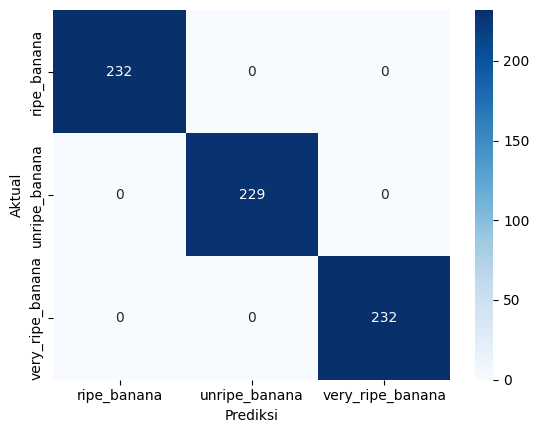

In [5]:
loss, acc = model2.evaluate(test_ds)
print(f"Akurasi data uji: {acc*100:.2f}%")

y_true = np.concatenate([y.numpy() for _, y in test_ds])
y_pred = np.argmax(model2.predict(test_ds), axis=1)

print(classification_report(y_true, y_pred, target_names=kelas))
sns.heatmap(confusion_matrix(y_true, y_pred), annot=True, fmt="d", cmap="Blues",
            xticklabels=kelas, yticklabels=kelas)
plt.xlabel("Prediksi"); plt.ylabel("Aktual"); plt.show()